# Plant Pathology 2020 — ResNet50 com Transfer Learning, Fine-Tuning e SHAP

Pipeline completo:

1. Divisão **treino / validação / teste (70/15/15)**, estratificada
2. **Data augmentation** apenas no treino
3. **Pesos de classe** para o desbalanceamento (múltiplas doenças — `multiple_diseases` — ≈ 5% das imagens)
4. **Fase 1:** ResNet50 (ImageNet) congelada, treinando só a cabeça de classificação
5. **Fase 2:** *fine-tuning* do último bloco convolucional (`conv5`) com taxa de aprendizado baixa
6. Avaliação final **no conjunto de teste** (acurácia, macro F1, ROC-AUC, matriz de confusão)
7. Explicabilidade com **SHAP** (`GradientExplainer`)

> Por causa do desbalanceamento, as métricas principais são o **macro F1** e o **recall de múltiplas doenças**, e não só a acurácia global.

**Ambiente de execução:** use GPU (Ambiente de execução → Alterar tipo → T4 GPU).

# Importações

In [1]:
!pip install -q shap

In [2]:
import os
import shutil
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Semente fixa para reprodutibilidade (split, embaralhamento, pesos iniciais da cabeça)
SEED = 42
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# Montar o Google Drive

In [3]:
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR = '/content/drive/MyDrive/plant-pathology-2020-fgvc7'
GRAPHS_DIR = '/content/drive/MyDrive/plant_pathology_graphs'
MODELS_DIR = '/content/drive/MyDrive/plant_pathology_models'
os.makedirs(GRAPHS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

# Prefixo dos pesos e relatórios salvos (o mesmo nome do modelo publicado na release v1.1.0)
PREFIXO = 'resnet50_finetune'

Mounted at /content/drive


# Carregamento do DataFrame

O `test.csv` do Kaggle **não possui rótulos** (era o conjunto da competição), por isso o conjunto de teste deste trabalho é separado a partir do `train.csv`.

In [4]:
train_df = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))

target_cols = [col for col in train_df.columns if col != 'image_id']
train_df['label'] = train_df[target_cols].idxmax(axis=1)
class_names = sorted(train_df['label'].unique())
class_to_idx = {name: i for i, name in enumerate(class_names)}
train_df['label_idx'] = train_df['label'].map(class_to_idx)
NUM_CLASSES = len(class_names)

print("Total de imagens:", len(train_df))
print("Mapeamento de classes:", class_to_idx)
print("\nDistribuição das classes:")
print(train_df['label'].value_counts())

Total de imagens: 1821
Mapeamento de classes: {'healthy': 0, 'multiple_diseases': 1, 'rust': 2, 'scab': 3}

Distribuição das classes:
label
rust                 622
scab                 592
healthy              516
multiple_diseases     91
Name: count, dtype: int64


# Cópia das imagens para o disco local do Colab

Ler as imagens direto do Drive é lento (cada época pode levar vários minutos só de leitura). Copiamos apenas as imagens de treino uma vez para `/content`, o que acelera todas as épocas.

In [6]:
DRIVE_IMAGES_DIR = os.path.join(DATA_DIR, 'images')
LOCAL_IMAGES_DIR = '/content/images'
os.makedirs(LOCAL_IMAGES_DIR, exist_ok=True)

for image_id in train_df['image_id']:
    destino = os.path.join(LOCAL_IMAGES_DIR, f"{image_id}.jpg")
    if not os.path.exists(destino):
        shutil.copy(os.path.join(DRIVE_IMAGES_DIR, f"{image_id}.jpg"), destino)

train_df['image_path'] = train_df['image_id'].apply(
    lambda x: os.path.join(LOCAL_IMAGES_DIR, f"{x}.jpg")
)
print("Imagens disponíveis localmente:", len(os.listdir(LOCAL_IMAGES_DIR)))

Imagens disponíveis localmente: 1821


# Divisão Treino / Validação / Teste (70/15/15)

- **Treino:** a rede aprende com ele.
- **Validação:** acompanha o treino; usada pelo EarlyStopping, ReduceLROnPlateau e ModelCheckpoint para escolher a melhor época.
- **Teste:** usado **uma única vez**, no final, para as métricas reportadas.

A divisão é feita em duas etapas com `train_test_split` **estratificado**, garantindo a mesma proporção de cada classe nos três conjuntos (importante para a classe minoritária). O `validation_split` do `model.fit` não foi usado porque ele não funciona com `tf.data.Dataset` e, mesmo com arrays, pega os últimos exemplos sem embaralhar e sem estratificar.

In [7]:
# Nomes em português usados apenas na exibição dos resultados.
# Os nomes internos (class_names) continuam em inglês, como no train.csv.
nomes_pt = {
    'healthy': 'saudável',
    'multiple_diseases': 'múltiplas doenças',
    'rust': 'ferrugem',
    'scab': 'sarna',
}
class_names_pt = [nomes_pt[nome] for nome in class_names]

train_paths, temp_paths, train_labels_arr, temp_labels_arr = train_test_split(
    train_df['image_path'].values,
    train_df['label_idx'].values,
    test_size=0.30,
    random_state=SEED,
    stratify=train_df['label_idx'].values
)

val_paths, test_paths, val_labels_arr, test_labels_arr = train_test_split(
    temp_paths,
    temp_labels_arr,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_labels_arr
)

train_labels_oh = tf.keras.utils.to_categorical(train_labels_arr, num_classes=NUM_CLASSES)
val_labels_oh = tf.keras.utils.to_categorical(val_labels_arr, num_classes=NUM_CLASSES)
test_labels_oh = tf.keras.utils.to_categorical(test_labels_arr, num_classes=NUM_CLASSES)


def contar(labels):
    return (
        pd.Series(labels).value_counts().sort_index()
        .rename(index=dict(enumerate(class_names_pt)))
    )


distribuicao = pd.DataFrame({
    'treino': contar(train_labels_arr),
    'validação': contar(val_labels_arr),
    'teste': contar(test_labels_arr),
})
distribuicao.loc['total'] = distribuicao.sum()
display(distribuicao)

,treino,validação,teste
saudável,361,77,78
múltiplas doenças,64,14,13
ferrugem,435,93,94
sarna,414,89,89
total,1274,273,274


# Pipeline `tf.data` com Data Augmentation e Preprocessing ImageNet

- As imagens são redimensionadas para **512×512** (as lesões são pequenas; resoluções menores perdem detalhe).
- **Data augmentation** é aplicada **somente no treino**: inversões horizontal/vertical (uma folha não tem orientação "correta"), pequenas rotações, zoom e variação de brilho. Isso aumenta artificialmente a variedade de exemplos, o que ajuda principalmente a classe minoritária.
- Depois da augmentation aplica-se o `preprocess_input` da ResNet50, que deixa a imagem no mesmo formato usado no treino da ImageNet (BGR com a média de cada canal subtraída). Sem ele os pesos pré-treinados não funcionam corretamente.
- A augmentation fica no pipeline de dados e não dentro do modelo, de modo que o modelo salvo (e o SHAP) recebe apenas imagens limpas.

In [8]:
IMG_HEIGHT, IMG_WIDTH = 512, 512
BATCH_SIZE = 16


def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_HEIGHT, IMG_WIDTH])  # valores em [0, 255]
    return image, label


def load_and_preprocess_image(image_path, label):
    image, label = load_image(image_path, label)
    return preprocess_input(image), label


data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1, fill_mode="reflect"),
    layers.RandomZoom(0.1, fill_mode="reflect"),
    layers.RandomBrightness(0.1, value_range=(0, 255)),
], name="data_augmentation")


def augment_and_preprocess(images, labels):
    images = data_augmentation(images, training=True)
    return preprocess_input(images), labels


def make_dataset(paths, labels_oh, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels_oh))

    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.batch(BATCH_SIZE)
        ds = ds.map(augment_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    else:
        ds = ds.map(load_and_preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.batch(BATCH_SIZE)

    return ds.prefetch(tf.data.AUTOTUNE)


train_dataset = make_dataset(train_paths, train_labels_oh, training=True)
val_dataset = make_dataset(val_paths, val_labels_oh)
test_dataset = make_dataset(test_paths, test_labels_oh)  # sem shuffle: mantém a ordem de test_paths

### Visualização da Data Augmentation

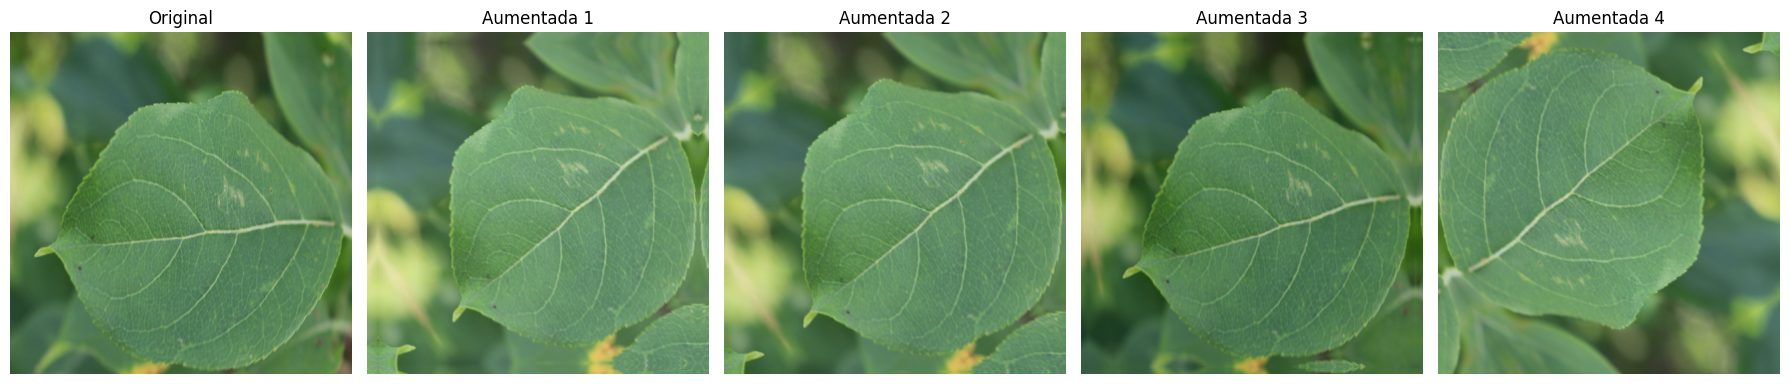

In [9]:
imagem_original, _ = load_image(train_paths[0], 0)

plt.figure(figsize=(18, 4))
plt.subplot(1, 5, 1)
plt.imshow(imagem_original.numpy().astype("uint8"))
plt.title("Original")
plt.axis("off")

for i in range(4):
    aumentada = data_augmentation(tf.expand_dims(imagem_original, 0), training=True)[0]
    plt.subplot(1, 5, i + 2)
    plt.imshow(np.clip(aumentada.numpy(), 0, 255).astype("uint8"))
    plt.title(f"Aumentada {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "resnet50_augmentation.png"), dpi=200, bbox_inches="tight")
plt.show()

# Pesos de Classes (Desbalanceamento)

`class_weight='balanced'` dá peso maior aos erros das classes raras na função de perda. Com isso, errar uma imagem de múltiplas doenças "custa" cerca de 5 vezes mais do que errar uma das classes majoritárias. Os pesos são calculados **apenas com o conjunto de treino**.

In [10]:
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels_arr),
    y=train_labels_arr
)
class_weights_dict = dict(enumerate(class_weights))

for idx, peso in class_weights_dict.items():
    print(f"{class_names_pt[idx]:<18} peso = {peso:.3f}")

saudável           peso = 0.882
múltiplas doenças  peso = 4.977
ferrugem           peso = 0.732
sarna              peso = 0.769


# Construção do Modelo

- Base: **ResNet50 pré-treinada na ImageNet**, sem a camada de classificação original (`include_top=False`).
- A base é chamada com `training=False`. Isso mantém as camadas de **BatchNormalization em modo de inferência** mesmo depois de descongelar camadas no fine-tuning, o que evita que as estatísticas aprendidas na ImageNet sejam destruídas por lotes pequenos (16 imagens).
- Cabeça: `GlobalAveragePooling2D → Dense(256, ReLU) → Dropout(0.4) → Dense(4, softmax)`.

In [11]:
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)
)
base_model.trainable = False

inputs = layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = models.Model(inputs, outputs, name="resnet50_plant")
model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "resnet50_plant"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 512, 512, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 16, 16, 2048)   │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,113,284 (91.98 MB)

 Trainable params: 525,572 (2.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

# Métricas e Callbacks

- Métricas acompanhadas: acurácia, ROC-AUC e **macro F1** (média simples do F1 das 4 classes, que dá o mesmo peso à classe minoritária).
- **ModelCheckpoint:** salva no Drive os pesos da época com menor `val_loss` (protege contra desconexão do Colab).
- **EarlyStopping:** interrompe quando a `val_loss` para de melhorar e restaura os melhores pesos.
- **ReduceLROnPlateau:** divide a taxa de aprendizado por 5 quando a `val_loss` estabiliza, permitindo ajustes mais finos.

A `val_loss` foi escolhida como critério por ser mais estável que o F1 de validação, que oscila bastante com poucas imagens da classe minoritária.

In [12]:
def criar_metricas():
    return [
        'accuracy',
        tf.keras.metrics.AUC(name='auc'),
        tf.keras.metrics.F1Score(average='macro', name='f1_macro'),
    ]


def criar_callbacks(checkpoint_path, patience_early_stop):
    return [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=checkpoint_path,
            save_weights_only=True,
            monitor='val_loss',
            mode='min',
            save_best_only=True,
            verbose=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=patience_early_stop,
            restore_best_weights=True,
            verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.2,
            patience=3,
            min_lr=1e-7,
            verbose=1
        ),
    ]

# Fase 1 — Treinamento da cabeça (base congelada)

Somente as camadas novas (Dense) são treinadas. A taxa de aprendizado pode ser mais alta (`1e-3`) porque os pesos da ResNet50 não são alterados.

In [13]:
CKPT_FASE1 = os.path.join(MODELS_DIR, f'{PREFIXO}_fase1.weights.h5')

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=criar_metricas()
)

history1 = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=30,
    class_weight=class_weights_dict,
    callbacks=criar_callbacks(CKPT_FASE1, patience_early_stop=7)
)

epocas_fase1 = len(history1.history['loss'])

Epoch 1/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4814 - auc: 0.7618 - f1_macro: 0.4165 - loss: 1.3424   
Epoch 1: val_loss improved from None to 0.68894, saving model to /content/drive/MyDrive/plant_pathology_models/resnet50_finetune_fase1.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/plant_pathology_models/resnet50_finetune_fase1.weights.h5
80/80 ━━━━━━━━━━━━━━━━━━━━ 115s 1s/step - accuracy: 0.5416 - auc: 0.7978 - f1_macro: 0.4885 - loss: 1.2185 - val_accuracy: 0.7729 - val_auc: 0.9312 - val_f1_macro: 0.6706 - val_loss: 0.6889 - learning_rate: 0.0010
Epoch 2/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 987ms/step - accuracy: 0.6910 - auc: 0.8935 - f1_macro: 0.6226 - loss: 0.8374
Epoch 2: val_loss improved from 0.68894 to 0.60213, saving model to /content/drive/MyDrive/plant_pathology_models/resnet50_finetune_fase1.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/plant_pathology_models/resnet50_finetune_fase1.weights.h5
80/80 ━━━━━━━━━━━━━━━

# Fase 2 — Fine-tuning do bloco `conv5`

As primeiras camadas da ResNet50 detectam padrões genéricos (bordas, texturas) que servem para qualquer imagem. As últimas camadas (`conv5`) são mais específicas da ImageNet. No fine-tuning, essas últimas camadas são **descongeladas** para se adaptarem às lesões das folhas.

- Taxa de aprendizado **100× menor** (`1e-5`), para ajustar os pesos pré-treinados sem destruí-los.
- As camadas de **BatchNormalization continuam congeladas**.
- O treino continua a partir dos melhores pesos da Fase 1.

In [14]:
base_model.trainable = True
for layer in base_model.layers:
    if not layer.name.startswith('conv5_') or isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

camadas_treinaveis = [l.name for l in base_model.layers if l.trainable and l.weights]
print(f"Camadas da ResNet50 descongeladas: {len(camadas_treinaveis)}")
print(camadas_treinaveis)

CKPT_FASE2 = os.path.join(MODELS_DIR, f'{PREFIXO}_fase2.weights.h5')

# É obrigatório recompilar após mudar o trainable
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=criar_metricas()
)
model.summary()

Camadas da ResNet50 descongeladas: 10
['conv5_block1_1_conv', 'conv5_block1_2_conv', 'conv5_block1_0_conv', 'conv5_block1_3_conv', 'conv5_block2_1_conv', 'conv5_block2_2_conv', 'conv5_block2_3_conv', 'conv5_block3_1_conv', 'conv5_block3_2_conv', 'conv5_block3_3_conv']


Model: "resnet50_plant"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 512, 512, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 16, 16, 2048)   │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,113,284 (91.98 MB)

 Trainable params: 15,479,044 (59.05 MB)

 Non-trainable params: 8,634,240 (32.94 MB)

In [15]:
history2 = model.fit(
    train_dataset,
    validation_data=val_dataset,
    initial_epoch=epocas_fase1,
    epochs=epocas_fase1 + 20,
    class_weight=class_weights_dict,
    callbacks=criar_callbacks(CKPT_FASE2, patience_early_stop=6)
)

Epoch 22/41
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8892 - auc: 0.9794 - f1_macro: 0.8364 - loss: 0.3906
Epoch 22: val_loss improved from None to 0.34567, saving model to /content/drive/MyDrive/plant_pathology_models/resnet50_finetune_fase2.weights.h5

Epoch 22: finished saving model to /content/drive/MyDrive/plant_pathology_models/resnet50_finetune_fase2.weights.h5
80/80 ━━━━━━━━━━━━━━━━━━━━ 136s 1s/step - accuracy: 0.8925 - auc: 0.9831 - f1_macro: 0.8253 - loss: 0.3465 - val_accuracy: 0.8645 - val_auc: 0.9796 - val_f1_macro: 0.7879 - val_loss: 0.3457 - learning_rate: 1.0000e-05
Epoch 23/41
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 974ms/step - accuracy: 0.8980 - auc: 0.9871 - f1_macro: 0.8294 - loss: 0.2872
Epoch 23: val_loss improved from 0.34567 to 0.31476, saving model to /content/drive/MyDrive/plant_pathology_models/resnet50_finetune_fase2.weights.h5

Epoch 23: finished saving model to /content/drive/MyDrive/plant_pathology_models/resnet50_finetune_fase2.weights.h5
80/80 ━━━━━━━━

# Carregar os melhores pesos e salvar o modelo

Por segurança, comparamos a melhor `val_loss` de cada fase e ficamos com o melhor modelo (normalmente o da Fase 2).

In [16]:
melhor_val_loss_fase1 = min(history1.history['val_loss'])
melhor_val_loss_fase2 = min(history2.history['val_loss'])

if melhor_val_loss_fase2 <= melhor_val_loss_fase1:
    model.load_weights(CKPT_FASE2)
    print(f"Usando pesos da Fase 2 (val_loss = {melhor_val_loss_fase2:.4f})")
else:
    model.load_weights(CKPT_FASE1)
    print(f"Fine-tuning não superou a Fase 1. Usando pesos da Fase 1 (val_loss = {melhor_val_loss_fase1:.4f})")

model_save_path = os.path.join(MODELS_DIR, f'{PREFIXO}_completo.keras')
model.save(model_save_path)
print(f"Modelo completo salvo em: {model_save_path}")

Usando pesos da Fase 2 (val_loss = 0.2590)
Modelo completo salvo em: /content/drive/MyDrive/plant_pathology_models/resnet50_finetune_completo.keras


# Curvas de Treinamento

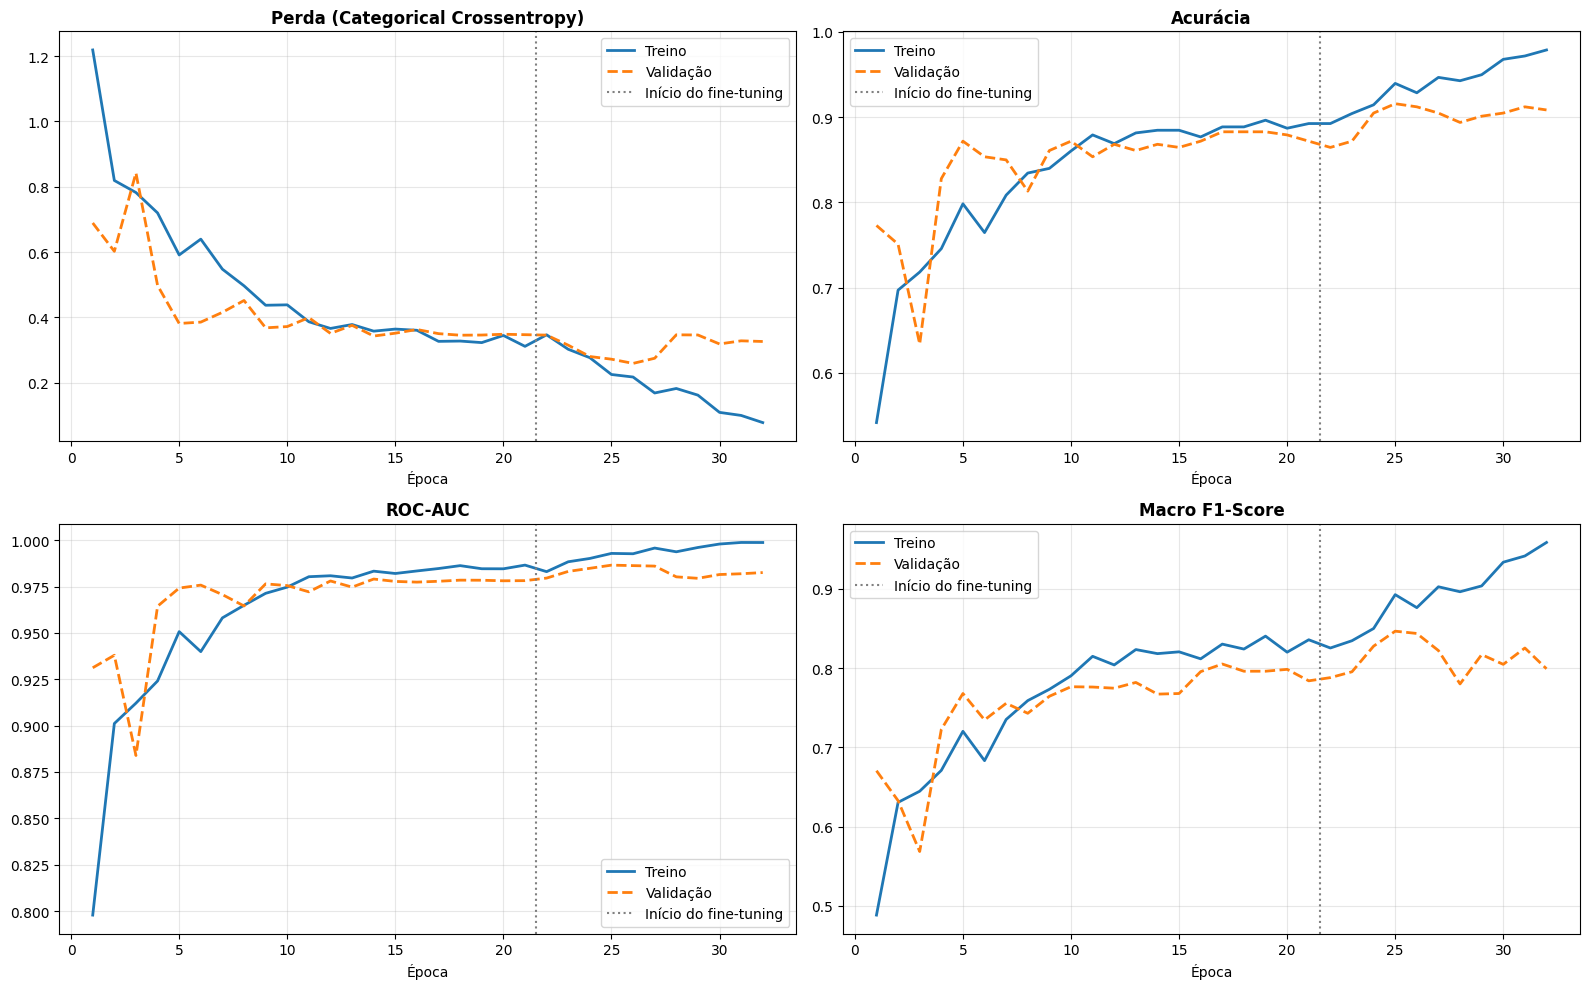

In [17]:
history_df = pd.concat(
    [pd.DataFrame(history1.history), pd.DataFrame(history2.history)],
    ignore_index=True
)
history_df.index = history_df.index + 1  # épocas começando em 1

graficos = [
    ("loss", "Perda (Categorical Crossentropy)"),
    ("accuracy", "Acurácia"),
    ("auc", "ROC-AUC"),
    ("f1_macro", "Macro F1-Score"),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, (metrica, titulo) in zip(axes.flat, graficos):
    ax.plot(history_df[metrica], label="Treino", lw=2)
    ax.plot(history_df[f"val_{metrica}"], label="Validação", lw=2, linestyle="--")
    ax.axvline(epocas_fase1 + 0.5, color="gray", linestyle=":", label="Início do fine-tuning")
    ax.set_title(titulo, fontweight="bold")
    ax.set_xlabel("Época")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "resnet50_curvas.png"), dpi=300, bbox_inches="tight")
plt.show()

# Avaliação Final no Conjunto de Teste

Estas são as métricas que devem ir para o relatório: o conjunto de teste não foi usado em nenhuma decisão do treinamento.

In [18]:
test_preds_prob = model.predict(test_dataset, verbose=0)
test_preds_idx = test_preds_prob.argmax(axis=1)
test_true_idx = test_labels_arr

report_dict = classification_report(
    test_true_idx,
    test_preds_idx,
    target_names=class_names_pt,
    output_dict=True,
    zero_division=0
)
report_df = pd.DataFrame(report_dict).transpose()
report_df = report_df.rename(
    index={'accuracy': 'acurácia', 'macro avg': 'média macro', 'weighted avg': 'média ponderada'},
    columns={'precision': 'precisão', 'recall': 'recall', 'f1-score': 'F1-score', 'support': 'suporte'}
)
display(report_df.round(4))
report_df.to_csv(os.path.join(MODELS_DIR, f"{PREFIXO}_classification_report_teste.csv"))

overall_acc = report_dict["accuracy"]
macro_f1 = report_dict["macro avg"]["f1-score"]
macro_auc = roc_auc_score(test_labels_oh, test_preds_prob, average="macro", multi_class="ovr")
recall_md = report_dict[nomes_pt["multiple_diseases"]]["recall"]

print("\n--- Resumo de Métricas Globais (Teste) ---")
print(f"Acurácia Global:              {overall_acc * 100:.2f}%")
print(f"Macro F1-Score:               {macro_f1 * 100:.2f}%")
print(f"Mean ROC-AUC (Macro):         {macro_auc * 100:.2f}%")
print(f"Recall multiple_diseases:     {recall_md * 100:.2f}%")

print("\nROC-AUC por classe (um-contra-todos):")
for c, nome in enumerate(class_names_pt):
    auc_c = roc_auc_score(test_labels_oh[:, c], test_preds_prob[:, c])
    print(f"  {nome:<18} {auc_c * 100:.2f}%")

,precisão,recall,F1-score,suporte
saudável,0.9333,0.8974,0.9150,78.0000
múltiplas doenças,0.5000,0.9231,0.6486,13.0000
ferrugem,0.9773,0.9149,0.9451,94.0000
sarna,0.9195,0.8989,0.9091,89.0000
acurácia,0.9051,0.9051,0.9051,0.9051
média macro,0.8325,0.9086,0.8545,274.0000
média ponderada,0.9234,0.9051,0.9108,274.0000



--- Resumo de Métricas Globais (Teste) ---
Acurácia Global:              90.51%
Macro F1-Score:               85.45%
Mean ROC-AUC (Macro):         98.84%
Recall multiple_diseases:     92.31%

ROC-AUC por classe (um-contra-todos):
  saudável           99.25%
  múltiplas doenças  97.73%
  ferrugem           99.69%
  sarna              98.68%


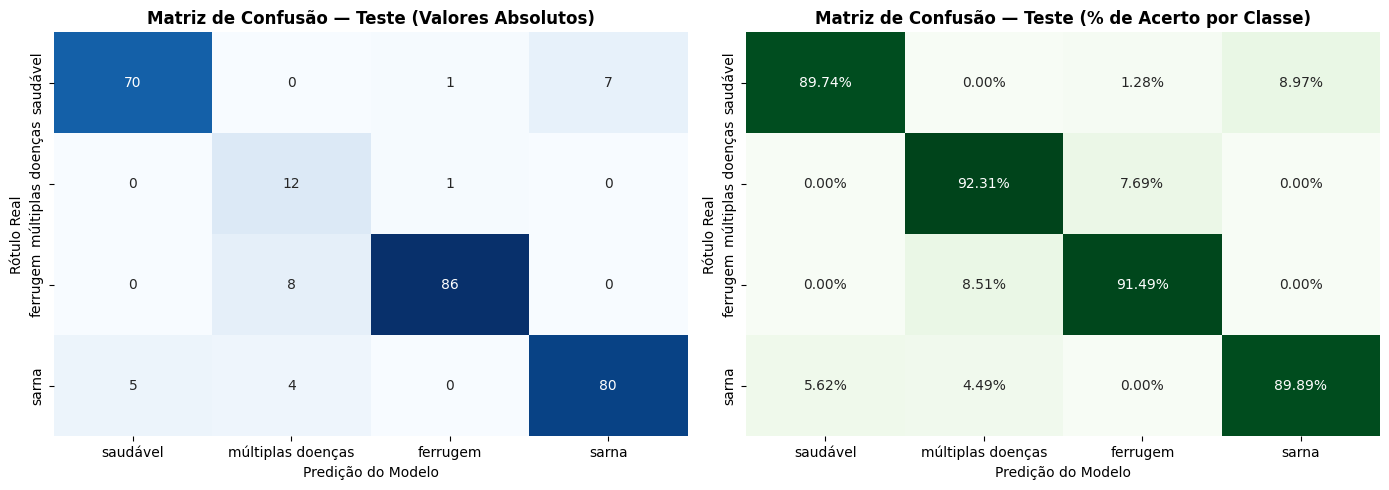

In [19]:
cm_raw = confusion_matrix(test_true_idx, test_preds_idx)
cm_norm = confusion_matrix(test_true_idx, test_preds_idx, normalize="true")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm_raw, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=class_names_pt, yticklabels=class_names_pt)
axes[0].set_title("Matriz de Confusão — Teste (Valores Absolutos)", fontweight="bold")
axes[0].set_xlabel("Predição do Modelo")
axes[0].set_ylabel("Rótulo Real")

sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap="Greens", cbar=False, ax=axes[1],
            xticklabels=class_names_pt, yticklabels=class_names_pt)
axes[1].set_title("Matriz de Confusão — Teste (% de Acerto por Classe)", fontweight="bold")
axes[1].set_xlabel("Predição do Modelo")
axes[1].set_ylabel("Rótulo Real")

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "resnet50_matriz_confusao.png"), dpi=300, bbox_inches="tight")
plt.show()

# Explicabilidade com SHAP

O **SHAP** (*SHapley Additive exPlanations*) estima a contribuição de cada pixel para a previsão do modelo. Aqui é usado o `GradientExplainer`, que combina gradientes da rede com um conjunto de imagens de referência (*background*) retirado do treino.

Na leitura dos mapas:
- **Vermelho:** pixels que aumentam a probabilidade daquela classe.
- **Azul:** pixels que diminuem a probabilidade daquela classe.

Para cada imagem são mostrados os mapas das **4 classes**, o que permite ver, por exemplo, que região faz o modelo hesitar entre ferrugem e múltiplas doenças. São escolhidos **um acerto de cada classe** e **até dois erros** (priorizando múltiplas doenças), todos do conjunto de teste.

A pergunta principal para a análise: o modelo olha para as **lesões** da folha, ou para o **fundo** e as bordas da foto?

> As imagens são 512×512 (16× mais pixels que 128×128), então o *background* é pequeno e o `batch_size` do explainer é baixo para caber na memória da GPU. Se faltar memória, reduza `N_BACKGROUND` ou `NSAMPLES`.

In [21]:
N_BACKGROUND = 20
NSAMPLES = 100

# Background: imagens aleatórias do treino, sem augmentation
rng = np.random.default_rng(SEED)
indices_background = rng.choice(len(train_paths), size=N_BACKGROUND, replace=False)
background = np.stack([
    load_and_preprocess_image(train_paths[i], 0)[0].numpy()
    for i in indices_background
])

# Amostras do teste: 1 acerto de cada classe + até 2 erros (priorizando multiple_diseases)
idx_md = class_to_idx['multiple_diseases']
acertos = np.where(test_preds_idx == test_true_idx)[0]
erros = np.where(test_preds_idx != test_true_idx)[0]

indices_shap = []
for c in range(NUM_CLASSES):
    candidatos = [i for i in acertos if test_true_idx[i] == c]
    if candidatos:
        indices_shap.append(candidatos[0])

erros_md = [i for i in erros if test_true_idx[i] == idx_md]
erros_outros = [i for i in erros if test_true_idx[i] != idx_md]
indices_shap += (erros_md + erros_outros)[:2]

test_sample = np.stack([
    load_and_preprocess_image(test_paths[i], 0)[0].numpy()
    for i in indices_shap
])
print(f"Imagens selecionadas para o SHAP: {len(indices_shap)}")

Imagens selecionadas para o SHAP: 6


In [22]:
explainer = shap.GradientExplainer(model, background, batch_size=8)
shap_values = explainer.shap_values(test_sample, nsamples=NSAMPLES)
print("Formato dos valores SHAP:", np.asarray(shap_values).shape)

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_180
Received: inputs=['Tensor(shape=(6, 512, 512, 3))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_180
Received: inputs=['Tensor(shape=(8, 512, 512, 3))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_180
Received: inputs=['Tensor(shape=(4, 512, 512, 3))']
  warnings.warn(msg)


Formato dos valores SHAP: (6, 512, 512, 3, 4)


[ACERTO] Real: saudável | Prevista: saudável | Arquivo: Train_924.jpg
Probabilidades: saudável: 99.9%, múltiplas doenças: 0.0%, ferrugem: 0.1%, sarna: 0.0%


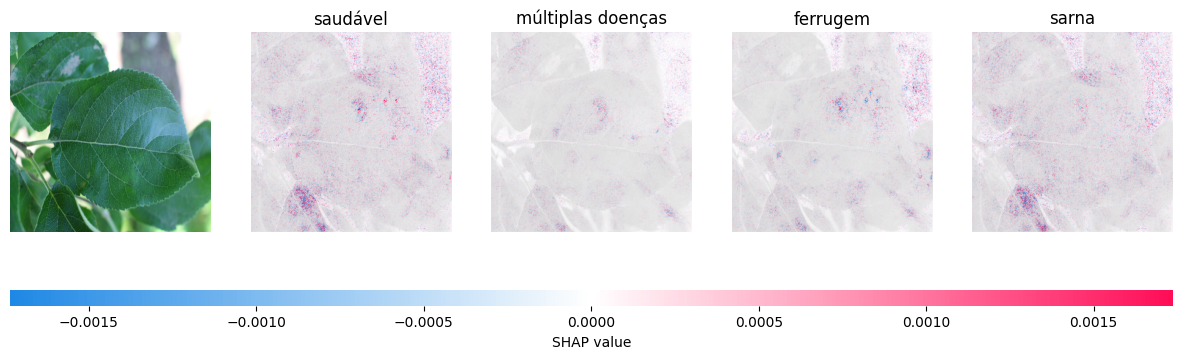

[ACERTO] Real: múltiplas doenças | Prevista: múltiplas doenças | Arquivo: Train_170.jpg
Probabilidades: saudável: 0.0%, múltiplas doenças: 68.5%, ferrugem: 31.5%, sarna: 0.0%


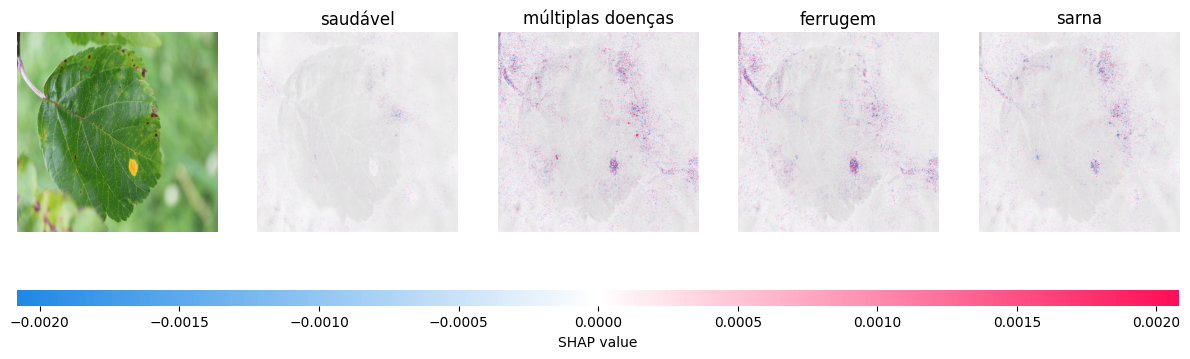

[ACERTO] Real: ferrugem | Prevista: ferrugem | Arquivo: Train_1775.jpg
Probabilidades: saudável: 0.0%, múltiplas doenças: 0.9%, ferrugem: 99.1%, sarna: 0.0%


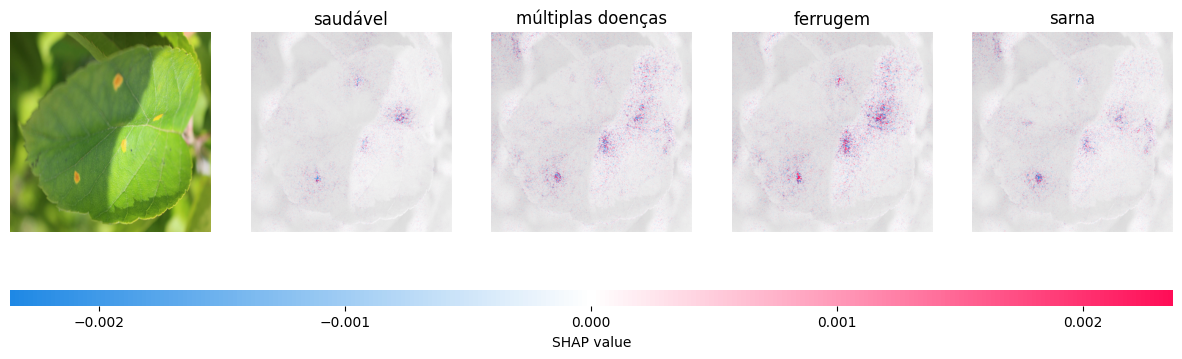

[ACERTO] Real: sarna | Prevista: sarna | Arquivo: Train_280.jpg
Probabilidades: saudável: 0.0%, múltiplas doenças: 0.0%, ferrugem: 0.0%, sarna: 100.0%


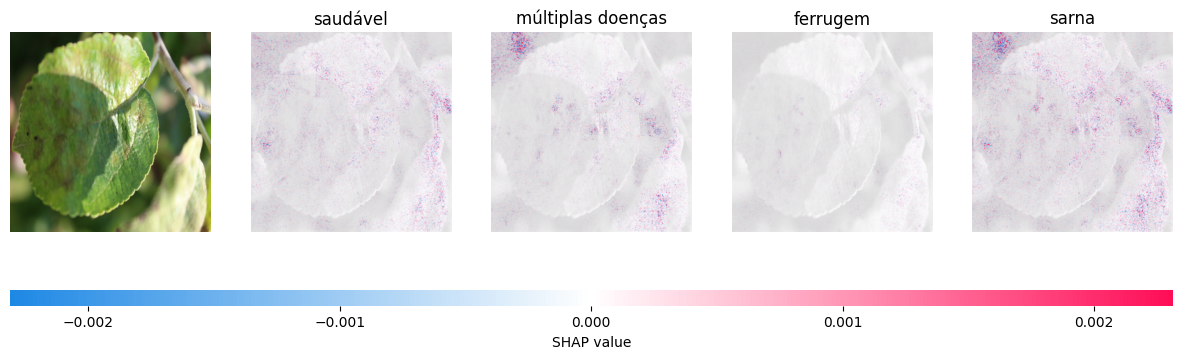

[ERRO] Real: múltiplas doenças | Prevista: ferrugem | Arquivo: Train_645.jpg
Probabilidades: saudável: 0.0%, múltiplas doenças: 8.2%, ferrugem: 91.8%, sarna: 0.0%


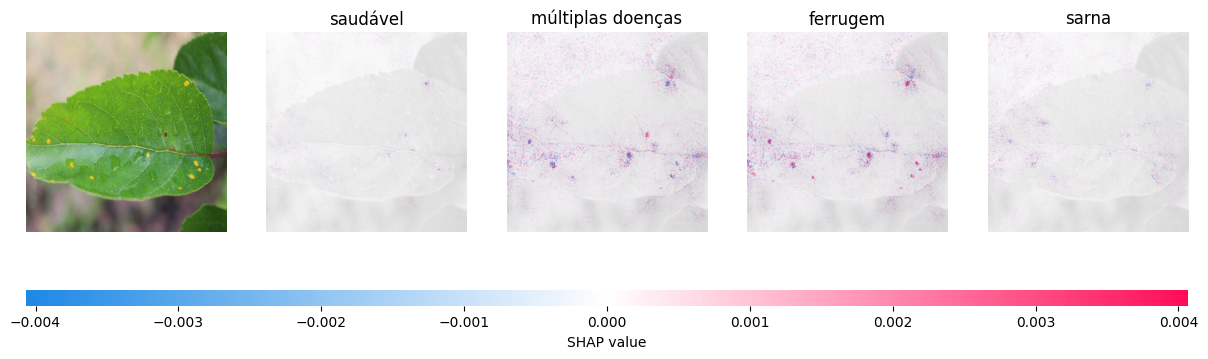

[ERRO] Real: saudável | Prevista: sarna | Arquivo: Train_1153.jpg
Probabilidades: saudável: 20.4%, múltiplas doenças: 33.7%, ferrugem: 2.8%, sarna: 43.0%


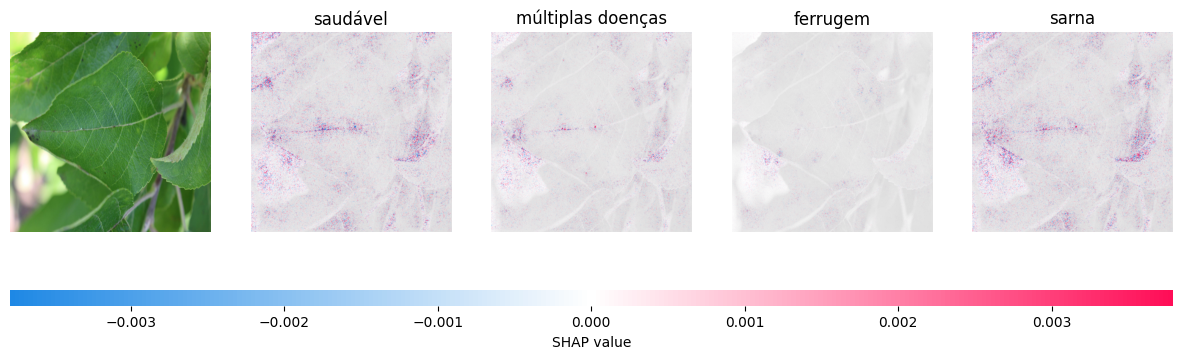

In [23]:
def shap_da_classe(shap_values, i, c):
    # O formato devolvido muda entre versões do SHAP: lista por classe ou array com a classe no último eixo
    if isinstance(shap_values, list):
        return shap_values[c][i:i+1]

    valores = np.asarray(shap_values)
    if valores.ndim == 5:
        return valores[i:i+1, ..., c]

    raise ValueError(f"Formato SHAP inesperado: {valores.shape}")


def desfazer_preprocess(imagens):
    # preprocess_input da ResNet50: RGB -> BGR e subtração da média de cada canal da ImageNet
    imagens = imagens.copy() + np.array([103.939, 116.779, 123.68])
    imagens = imagens[..., ::-1]
    return np.clip(imagens, 0, 255).astype(np.uint8)


for k, i in enumerate(indices_shap):
    real = class_names_pt[test_true_idx[i]]
    prevista = class_names_pt[test_preds_idx[i]]
    resultado = "ACERTO" if real == prevista else "ERRO"

    print("=" * 80)
    print(f"[{resultado}] Real: {real} | Prevista: {prevista} | Arquivo: {os.path.basename(test_paths[i])}")
    print("Probabilidades: " + ", ".join(
        f"{nome}: {test_preds_prob[i, c] * 100:.1f}%" for c, nome in enumerate(class_names_pt)
    ))

    valores_imagem = [shap_da_classe(shap_values, k, c) for c in range(NUM_CLASSES)]

    shap.image_plot(
        valores_imagem,
        desfazer_preprocess(test_sample[k:k+1]),
        labels=np.array([class_names_pt]),
        show=False
    )
    # Nome do arquivo com o nome interno (sem acento nem espaço)
    plt.savefig(
        os.path.join(GRAPHS_DIR, f"resnet50_shap_{k}_{resultado.lower()}_{class_names[test_true_idx[i]]}.png"),
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()

# Pontos para a discussão no relatório

- **Por que transfer learning:** com cerca de 1.270 imagens de treino, treinar uma rede profunda do zero tende a gerar overfitting e validação instável. Os pesos pré-treinados na ImageNet já trazem detectores de bordas e texturas.
- **Por que duas fases:** treinar primeiro só a cabeça evita que gradientes grandes de uma camada recém-inicializada estraguem os pesos pré-treinados. Depois, o fine-tuning com taxa baixa adapta o bloco `conv5` às lesões.
- **Desbalanceamento:** pesos de classe + data augmentation + avaliação por **macro F1** e **recall por classe**, porque a acurácia global esconde o desempenho em múltiplas doenças.
- **Limitação:** o teste tem apenas 13 imagens de múltiplas doenças, então cada acerto ou erro altera o recall dessa classe em cerca de 7,7 pontos percentuais.
- **SHAP:** discutir se as regiões em vermelho coincidem com as lesões e o que os erros revelam. No teste, uma folha de múltiplas doenças foi classificada como ferrugem (91,8%), o que é coerente com essa classe reunir folhas com mais de uma doença, muitas vezes incluindo ferrugem.